# 导星仿真单星 stamp 满阱饱和评估

本 notebook 汇总 31x31 单星导星仿真 stamp 的推导、复现实验代码、参数表、结果表和报告图。目标是判断在加入 PSF 卷积、背景光、杂散光、光子噪声、暗电流、读出噪声、满阱裁剪、偏置和 12 bit ADC 后，不同星等的星点是否出现饱和像素。

结论摘要：在 0.5 等网格上，`mag=10.5` 出现偶发满阱饱和，`mag=10.0` 及更亮星等在本次 500 次噪声实现中全部饱和。

In [10]:
from pathlib import Path
import importlib.util
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

REPO_ROOT = Path('/home/liyang/ET7/ET-fsgsim')
RESULT_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep')
SWEEP_SCRIPT = REPO_ROOT / 'scripts' / 'guide_stamp_saturation_sweep.py'
SUMMARY_CSV = RESULT_DIR / 'saturation_summary.csv'
METADATA_JSON = RESULT_DIR / 'saturation_metadata.json'
STAMPS_NPZ = RESULT_DIR / 'single_star_stamps_31x31.npz'
ASSET_DIR = REPO_ROOT / 'notebooks' / 'guide_star_saturation_report_files'
ASSET_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 200,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

for path in [SWEEP_SCRIPT, SUMMARY_CSV, METADATA_JSON, STAMPS_NPZ]:
    if not path.exists():
        raise FileNotFoundError(path)

print(f'Repo root: {REPO_ROOT}')
print(f'Result directory: {RESULT_DIR}')

Repo root: /home/liyang/ET7/ET-fsgsim
Result directory: /home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep


## 物理模型和单位约定

恒星电子率使用 Photsim7 的 ET 星等零点：

$$
R_\star(m)=1.11\times10^4\,10^{-0.4(m-12.5)}\quad [e^-\,s^{-1}]
$$

单帧曝光时间为 $t_\mathrm{exp}=0.25\,s$，所以单星总电子数为：

$$
N_\star(m)=R_\star(m)t_\mathrm{exp}
$$

背景面亮度为 $22\,\mathrm{mag\,arcsec^{-2}}$，按像元角面积换算为每像素背景电子率：

$$
R_\mathrm{bg}=R_\mathrm{ET}(22)\,s_\mathrm{pix}^2
$$

其中 $s_\mathrm{pix}=3.146\,\mathrm{arcsec\,pix^{-1}}$。本实验中暗电流和杂散光沿用导星基线：总计 $10\,e^-\,s^{-1}\,pix^{-1}$，拆成 $5+5$。

每个像素在满阱裁剪前的电荷为：

$$
Q = \mathrm{Pois}(I_\star) + \mathrm{Pois}(N_\mathrm{bg}) + \mathrm{Pois}(N_\mathrm{scatter}) + \mathrm{Pois}(N_\mathrm{dark})
$$

饱和判据定义为满阱裁剪前 $Q\ge1800\,e^-$。随后再做满阱裁剪、读出噪声、gain 转 ADU、加偏置和 12 bit ADC。读出噪声统一以 $e^-\,pix^{-1}$ 表示，本实验取 $\sigma_\mathrm{read}=5\,e^-\,pix^{-1}$。

### 主探12.5等星，曝光6.5小时，6个探测器总共11100*60*60*6.5*6=1558440000个电子（15.5亿）

In [11]:
summary = pd.read_csv(SUMMARY_CSV)
with METADATA_JSON.open('r', encoding='utf-8') as handle:
    meta = json.load(handle)
stamps = np.load(STAMPS_NPZ)

numeric_cols = [col for col in summary.columns if col != 'mag']
summary[numeric_cols] = summary[numeric_cols].apply(pd.to_numeric)
summary['mag'] = pd.to_numeric(summary['mag'])

first_any = meta['first_mag_with_any_saturated_realization']
first_all = meta['first_mag_with_all_realizations_saturated']

print(f'Loaded {len(summary)} magnitude grid points.')
print(f'First magnitude with any saturated realization: {first_any}')
print(f'First magnitude with all realizations saturated: {first_all}')

Loaded 11 magnitude grid points.
First magnitude with any saturated realization: 10.5
First magnitude with all realizations saturated: 10.0


In [12]:
param_rows = [
    ('Stamp size', f"{meta['stamp_size_pix']} x {meta['stamp_size_pix']} pix"),
    ('Subpixels Per Pixel Dim', meta['subpixels_per_pixel_dim']),
    ('PSF bundle', meta['psf_bundle_name']),
    ('PSF field ID', meta['psf_field_id']),
    ('Star center', meta['star_center_pix_zero_indexed']),
    ('Exposure', f"{meta['exposure_s']} s"),
    ('Pixel scale', f"{meta['pixel_scale_arcsec_per_pix']} arcsec/pix"),
    ('Sky background brightness', f"{meta['background_surface_brightness_mag_arcsec2']} mag/arcsec^2"),
    ('Background flux', f"{meta['background_flux_e_per_s_per_pix']:.6f} e/s/pix"),
    ('Background count per frame', f"{meta['background_counts_e_per_pix']:.6f} e/pix"),
    ('Scattered light', f"{meta['scattered_light_e_per_s_per_pix']:.3f} e/s/pix"),
    ('Dark current', f"{meta['dark_current_e_per_s_per_pix']:.3f} e/s/pix"),
    ('Readout noise', f"{meta['readout_noise_e_per_pix']:.3f} e/pix"),
    ('Full well', f"{meta['full_well_electrons']:.1f} e"),
    ('ADC', f"{meta['adc_bit_depth']} bit"),
    ('Bias', f"{meta['bias_level_adu']:.1f} ADU"),
    ('Gain', f"{meta['gain_electrons_per_adu']:.1f} e/ADU"),
    ('Realizations per mag', meta['n_realizations_per_mag']),
    ('Seed', meta['seed']),
]
param_df = pd.DataFrame(param_rows, columns=['Parameter', 'Value'])
display(param_df)
param_df.to_csv(ASSET_DIR / 'parameter_table.csv', index=False)

,Parameter,Value
0,Stamp size,31 x 31 pix
1,Subpixels Per Pixel Dim,1
2,PSF bundle,241006/D280mm-focus-guide6p5um
3,PSF field ID,7
4,Star center,"[15.0, 15.0]"
5,Exposure,0.25 s
6,Pixel scale,3.146 arcsec/pix
7,Sky background brightness,22.0 mag/arcsec^2
8,Background flux,17.411670 e/s/pix
9,Background count per frame,4.352917 e/pix


In [13]:
report_cols = [
    'mag',
    'photon_count_e_0p25s',
    'expected_peak_star_e',
    'max_charge_e_median',
    'max_charge_e_p95',
    'max_charge_e_max',
    'saturated_frames',
    'saturation_fraction',
    'max_saturated_pixels_in_frame',
]
report_table = summary[report_cols].copy()
report_table = report_table.rename(columns={
    'mag': 'mag',
    'photon_count_e_0p25s': 'total star e / frame',
    'expected_peak_star_e': 'expected peak e',
    'max_charge_e_median': 'median max charge e',
    'max_charge_e_p95': 'p95 max charge e',
    'max_charge_e_max': 'max charge e',
    'saturated_frames': 'sat frames',
    'saturation_fraction': 'sat fraction',
    'max_saturated_pixels_in_frame': 'max sat pix/frame',
})

display(
    report_table.style.format({
        'mag': '{:.1f}',
        'total star e / frame': '{:.1f}',
        'expected peak e': '{:.1f}',
        'median max charge e': '{:.1f}',
        'p95 max charge e': '{:.1f}',
        'max charge e': '{:.1f}',
        'sat fraction': '{:.3f}',
    }).background_gradient(subset=['sat fraction'], cmap='Reds')
)
report_table.to_csv(ASSET_DIR / 'saturation_report_table.csv', index=False)

,mag,total star e / frame,expected peak e,median max charge e,p95 max charge e,max charge e,sat frames,sat fraction,max sat pix/frame
0,14.0,697.0,66.0,73.0,87.0,104.0,0,0.000,0
1,13.5,1104.7,104.6,111.0,130.0,141.0,0,0.000,0
2,13.0,1750.9,165.8,172.0,191.0,205.0,0,0.000,0
3,12.5,2775.0,262.8,271.0,295.0,314.0,0,0.000,0
4,12.0,4398.1,416.5,422.0,458.1,483.0,0,0.000,0
5,11.5,6970.5,660.1,666.0,710.0,760.0,0,0.000,0
6,11.0,11047.5,1046.3,1055.0,1108.0,1162.0,0,0.000,0
7,10.5,17509.1,1658.2,1664.5,1733.1,1802.0,1,0.002,1
8,10.0,27750.0,2628.1,2636.0,2718.0,2799.0,500,1.000,2
9,9.5,43980.8,4165.3,4164.0,4277.1,4377.0,500,1.000,3


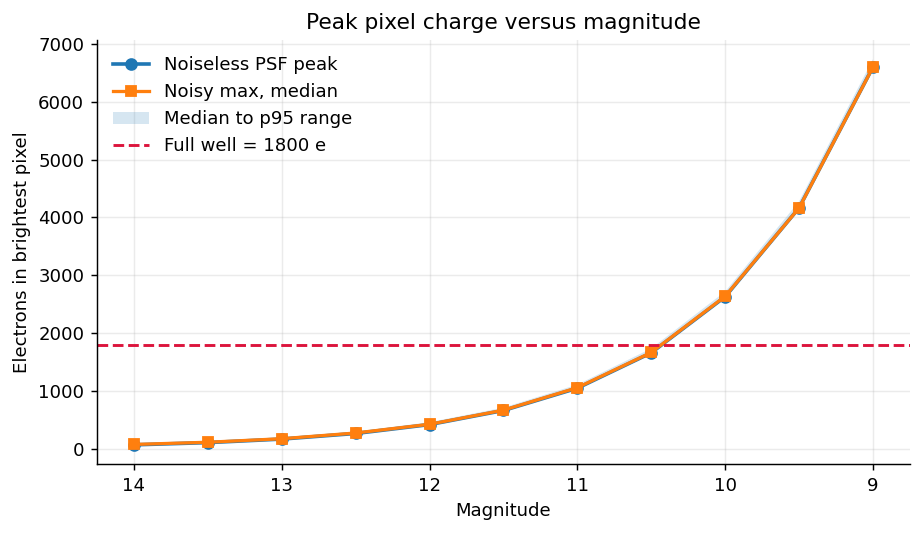

In [14]:
full_well = float(meta['full_well_electrons'])
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(summary['mag'], summary['expected_peak_star_e'], marker='o', lw=2, label='Noiseless PSF peak')
ax.plot(summary['mag'], summary['max_charge_e_median'], marker='s', lw=1.8, label='Noisy max, median')
ax.fill_between(
    summary['mag'],
    summary['max_charge_e_median'],
    summary['max_charge_e_p95'],
    alpha=0.18,
    label='Median to p95 range',
)
ax.axhline(full_well, color='crimson', ls='--', lw=1.6, label='Full well = 1800 e')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Electrons in brightest pixel')
ax.set_title('Peak pixel charge versus magnitude')
ax.invert_xaxis()
ax.legend(loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'peak_charge_vs_mag.png', bbox_inches='tight')
plt.show()

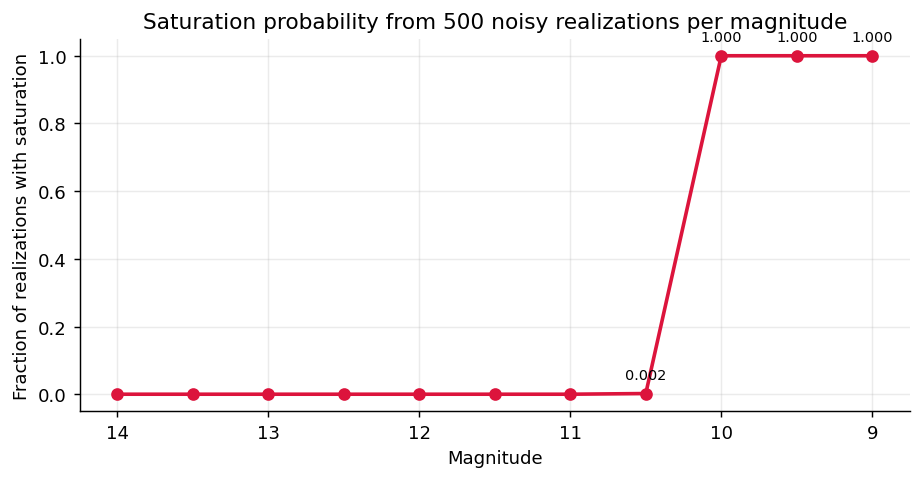

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(summary['mag'], summary['saturation_fraction'], marker='o', color='crimson', lw=2)
ax.set_xlabel('Magnitude')
ax.set_ylabel('Fraction of realizations with saturation')
ax.set_title('Saturation probability from 500 noisy realizations per magnitude')
ax.set_ylim(-0.05, 1.05)
ax.invert_xaxis()
for _, row in summary.iterrows():
    if row['saturation_fraction'] > 0:
        ax.annotate(
            f"{row['saturation_fraction']:.3f}",
            xy=(row['mag'], row['saturation_fraction']),
            xytext=(0, 8),
            textcoords='offset points',
            ha='center',
            fontsize=8,
        )
fig.tight_layout()
fig.savefig(ASSET_DIR / 'saturation_fraction_vs_mag.png', bbox_inches='tight')
plt.show()

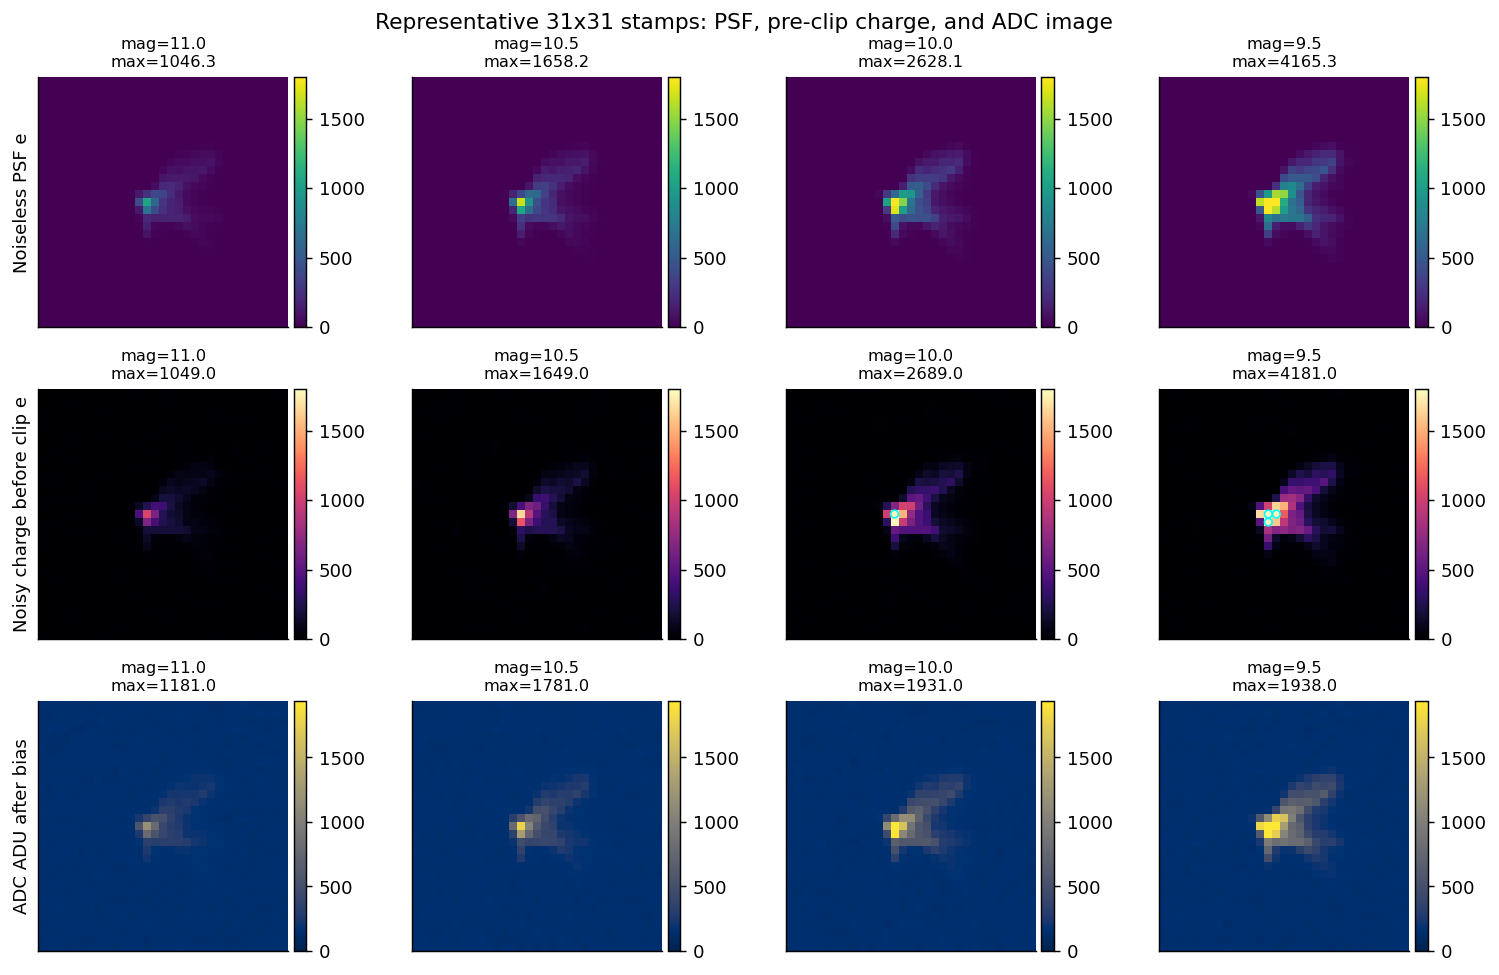

In [16]:
selected_mags = [11.0, 10.5, 10.0, 9.5]
fig, axes = plt.subplots(3, len(selected_mags), figsize=(11.5, 7.2), constrained_layout=True)
row_specs = [
    ('expected_star_e', 'Noiseless PSF e', 'viridis', full_well),
    ('charge_before_clip_e', 'Noisy charge before clip e', 'magma', full_well),
    ('adc_adu', 'ADC ADU after bias', 'cividis', full_well + meta['bias_level_adu']),
]

for col, mag in enumerate(selected_mags):
    for row, (suffix, label, cmap, vmax) in enumerate(row_specs):
        key = f'mag_{mag:.1f}_{suffix}'
        image = stamps[key]
        ax = axes[row, col]
        im = ax.imshow(image, origin='lower', cmap=cmap, vmin=0, vmax=vmax)
        if suffix == 'charge_before_clip_e':
            saturated = image >= full_well
            if np.any(saturated):
                yy, xx = np.where(saturated)
                ax.scatter(xx, yy, s=18, facecolors='none', edgecolors='cyan', linewidths=0.9)
        ax.set_title(f'mag={mag:.1f}\nmax={np.nanmax(image):.1f}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(label)
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)

fig.suptitle('Representative 31x31 stamps: PSF, pre-clip charge, and ADC image', y=1.02, fontsize=12)
fig.savefig(ASSET_DIR / 'representative_stamps.png', bbox_inches='tight')
plt.show()

## 关键实现细节

本实验使用 `scripts/guide_stamp_saturation_sweep.py` 作为可执行版本。局部 31x31 stamp 渲染时，PSF bundle 使用 `pad_to_detector_shape=False`。原因是 guide PSF 原生 stamp 是 25x25，若把三层 PSF bundle 直接 pad 到 31x31，会把坐标层也用 0 填充；局部采样时坐标范围退化，可能产生 NaN。

下面的代码单元保留了 notebook 内部复现入口：默认读取已经生成的 CSV/NPZ；如需从 notebook 内完整重跑，把 `FORCE_RERUN` 改成 `True`。

In [17]:
def load_sweep_module():
    spec = importlib.util.spec_from_file_location('guide_stamp_saturation_sweep', SWEEP_SCRIPT)
    module = importlib.util.module_from_spec(spec)
    assert spec is not None and spec.loader is not None
    spec.loader.exec_module(module)
    return module

sweep = load_sweep_module()

# 与脚本一致的核心流程，保留在 notebook 中便于报告复现。
def simulate_one_magnitude(mag, n_realizations=500, seed=None):
    rng = np.random.default_rng(meta['seed'] if seed is None else seed)
    psf_manager = sweep.make_psf_model_manager(device='cpu', float_precision=32)
    expected_star_e = sweep.render_expected_star(psf_manager, float(mag), 'cpu', 32)
    sim = sweep.simulate_realizations(
        expected_star_e=expected_star_e,
        rng=rng,
        n_realizations=n_realizations,
        background_counts_e=meta['background_counts_e_per_pix'],
        scattered_counts_e=meta['scattered_counts_e_per_pix'],
        dark_counts_e=meta['dark_counts_e_per_pix'],
    )
    max_charge_e = sim['charge_before_clip_e'].reshape(n_realizations, -1).max(axis=1)
    sat_pix = sim['saturated_pixels_per_frame']
    return {
        'mag': float(mag),
        'expected_peak_star_e': float(np.max(expected_star_e)),
        'expected_total_star_e': float(np.sum(expected_star_e)),
        'saturated_frames': int(np.count_nonzero(sat_pix > 0)),
        'saturation_fraction': float(np.mean(sat_pix > 0)),
        'max_charge_e_median': float(np.median(max_charge_e)),
        'max_charge_e_p95': float(np.percentile(max_charge_e, 95)),
        'max_charge_e_max': float(np.max(max_charge_e)),
    }

demo = simulate_one_magnitude(10.5, n_realizations=20, seed=meta['seed'])
display(pd.DataFrame([demo]))

,mag,expected_peak_star_e,expected_total_star_e,saturated_frames,saturation_fraction,max_charge_e_median,max_charge_e_p95,max_charge_e_max
0,10.5,1658.221558,17509.066424,0,0.0,1663.5,1718.3,1724.0


In [18]:
FORCE_RERUN = False
N_REALIZATIONS = int(meta['n_realizations_per_mag'])
PYTHON = Path('/home/liyang/anaconda3/envs/py311/bin/python')

if FORCE_RERUN:
    command = [
        str(PYTHON),
        str(SWEEP_SCRIPT),
        '--n-realizations',
        str(N_REALIZATIONS),
        '--output-dir',
        str(RESULT_DIR),
    ]
    completed = subprocess.run(command, cwd=REPO_ROOT, check=True, text=True, capture_output=True)
    print(completed.stdout)
else:
    print('FORCE_RERUN=False: using existing sweep products listed above.')

FORCE_RERUN=False: using existing sweep products listed above.


,mag,photon rate (e/s),total photo-electrons / 0.25 s,PSF stamp sum (e)
0,14.0,2788.2,697.0,697.0
1,13.5,4419.0,1104.7,1104.7
2,13.0,7003.6,1750.9,1750.9
3,12.5,11100.0,2775.0,2775.0
4,12.0,17592.3,4398.1,4398.1
5,11.5,27881.9,6970.5,6970.5
6,11.0,44189.9,11047.5,11047.5
7,10.5,70036.3,17509.1,17509.1
8,10.0,111000.0,27750.0,27750.0
9,9.5,175923.1,43980.8,43980.8


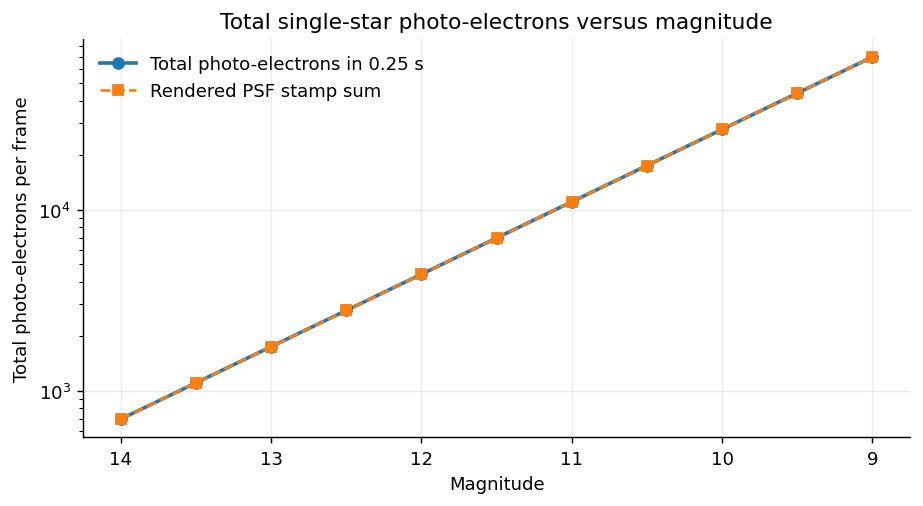

In [19]:
# 星等对应的总光子/光电子数表格和图
photon_table = summary[['mag', 'photon_rate_e_per_s', 'photon_count_e_0p25s', 'expected_total_star_e']].copy()
photon_table = photon_table.rename(columns={
    'mag': 'mag',
    'photon_rate_e_per_s': 'photon rate (e/s)',
    'photon_count_e_0p25s': 'total photo-electrons / 0.25 s',
    'expected_total_star_e': 'PSF stamp sum (e)',
})

display(
    photon_table.style.format({
        'mag': '{:.1f}',
        'photon rate (e/s)': '{:.1f}',
        'total photo-electrons / 0.25 s': '{:.1f}',
        'PSF stamp sum (e)': '{:.1f}',
    }).background_gradient(subset=['total photo-electrons / 0.25 s'], cmap='Blues')
)
photon_table.to_csv(ASSET_DIR / 'magnitude_total_photon_table.csv', index=False)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(
    photon_table['mag'],
    photon_table['total photo-electrons / 0.25 s'],
    marker='o',
    lw=2,
    label='Total photo-electrons in 0.25 s',
)
ax.plot(
    photon_table['mag'],
    photon_table['PSF stamp sum (e)'],
    marker='s',
    lw=1.5,
    ls='--',
    label='Rendered PSF stamp sum',
)
ax.set_yscale('log')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Total photo-electrons per frame')
ax.set_title('Total single-star photo-electrons versus magnitude')
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'total_photoelectrons_vs_mag.png', bbox_inches='tight')
plt.show()


In [ ]:
# 主探12.5等星，曝光6.5小时，6个探测器总共11100*60*60*6.5*6=1558440000个电子（15.5亿）

## 结论

在当前参数组合下，31x31 导星单星 stamp 的满阱饱和边界位于 10.5 等和 10.0 等之间。

- `mag=10.5`：500 次噪声实现中有 1 次出现至少 1 个饱和像素，属于偶发饱和。
- `mag=10.0`：500 次噪声实现全部出现饱和像素，可视为稳定饱和。
- `mag>=11.0`：本次 500 次噪声实现中未出现满阱饱和。

因此若报告中需要给出保守阈值，可以写作：在本仿真设置下，10.5 等附近已进入饱和风险区，10.0 等及更亮星点会稳定饱和。